<a href="https://colab.research.google.com/github/srangisetti27/TS/blob/main/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

In [2]:
df = pd.read_csv('/heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
df.shape

(1025, 14)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [5]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [6]:
df.duplicated().sum()

np.int64(723)

In [7]:
df = df.drop_duplicates()
df.shape

(302, 14)

In [8]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [9]:
df['target'].value_counts()

,count
target,
1,164
0,138


In [10]:
df.skew()

,0
age,-0.203743
sex,-0.786120
cp,0.493022
trestbps,0.716541
chol,1.147332
fbs,1.981201
restecg,0.169467
thalach,-0.532671
exang,0.737281
oldpeak,1.266173


<Axes: ylabel='chol'>

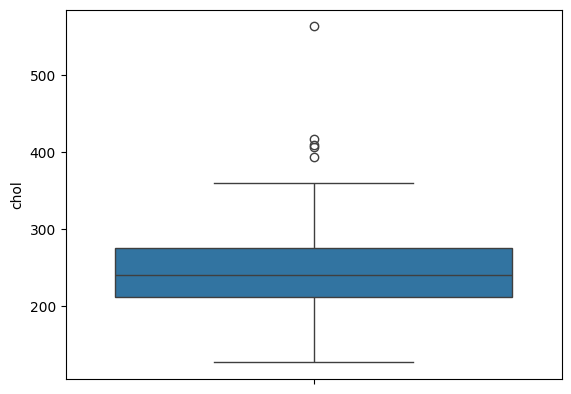

In [11]:
sns.boxplot(df['chol'])

<Axes: ylabel='trestbps'>

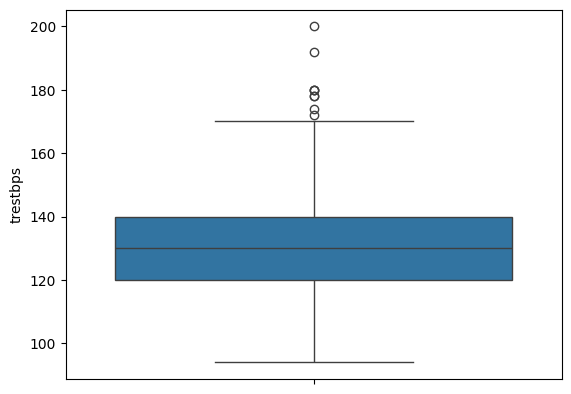

In [12]:
sns.boxplot(df['trestbps'])

<Axes: ylabel='thalach'>

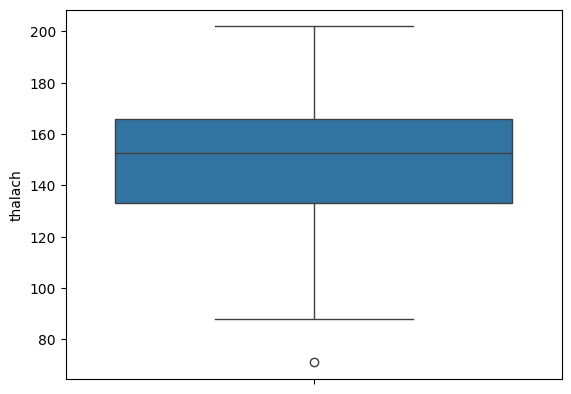

In [13]:
sns.boxplot(df['thalach'])

<Axes: ylabel='oldpeak'>

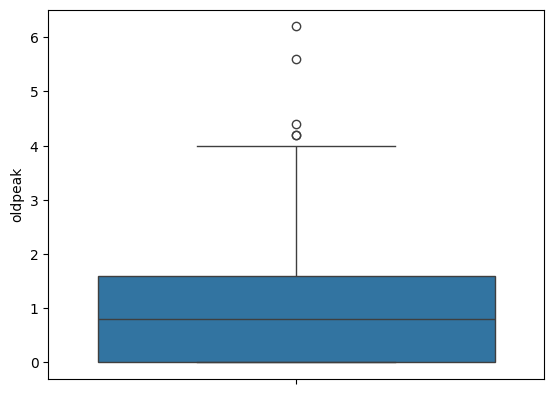

In [14]:
sns.boxplot(df['oldpeak'])

<Axes: xlabel='target', ylabel='age'>

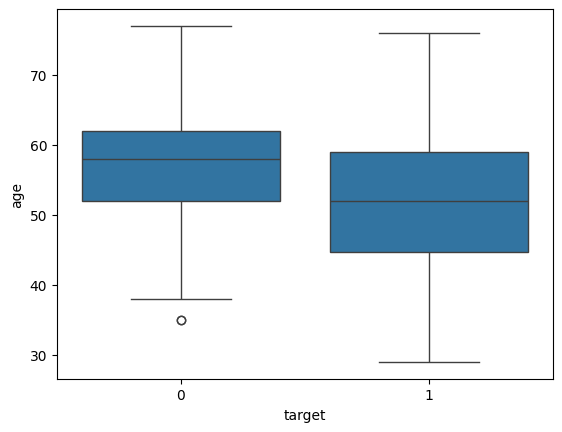

In [15]:
sns.boxplot(x=df['target'], y=df['age'])

<Axes: xlabel='target', ylabel='thalach'>

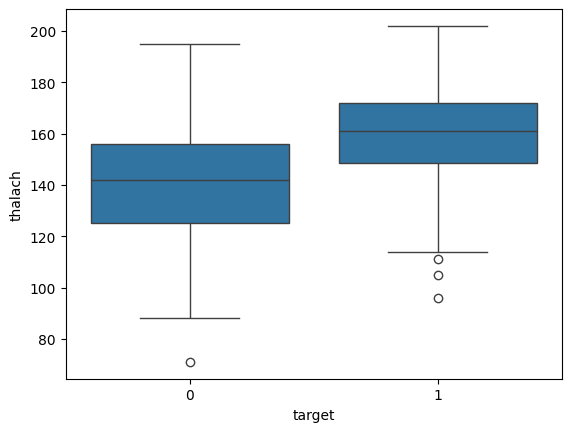

In [16]:
sns.boxplot(x=df['target'], y=df['thalach'])

<Axes: xlabel='target', ylabel='age'>

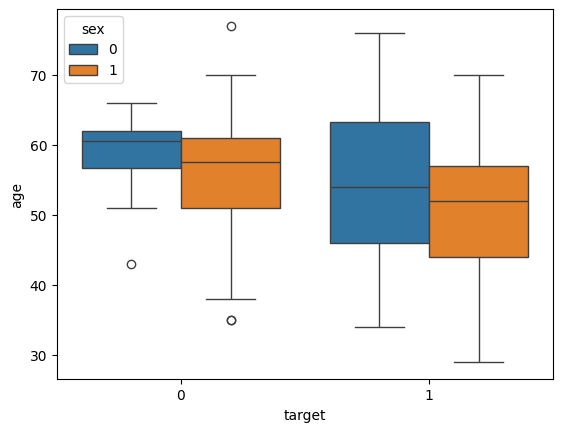

In [17]:
sns.boxplot(x=df['target'], y=df['age'], hue=df['sex'])

In [18]:
X = df.drop('target', axis=1)
y = df['target']

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [21]:
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

In [22]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

In [23]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [24]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

In [25]:
confusion_matrix(y_test, y_pred_lr)

array([[21, 11],
       [ 3, 26]])

In [26]:
confusion_matrix(y_test, y_pred_dt)

array([[25,  7],
       [ 9, 20]])

In [27]:
confusion_matrix(y_test, y_pred_rf)

array([[25,  7],
       [ 3, 26]])

In [28]:
confusion_matrix(y_test, y_pred_knn)

array([[22, 10],
       [ 6, 23]])

In [29]:
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
auc_lr = roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1])

In [30]:
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
auc_dt = roc_auc_score(y_test, dt.predict_proba(X_test)[:, 1])

In [31]:
acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
auc_rf = roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])

In [32]:
acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
auc_knn = roc_auc_score(y_test, knn.predict_proba(X_test)[:, 1])

In [33]:
results = pd.DataFrame({
    'Accuracy': [acc_lr, acc_dt, acc_rf, acc_knn],
    'Precision': [prec_lr, prec_dt, prec_rf, prec_knn],
    'Recall': [rec_lr, rec_dt, rec_rf, rec_knn],
    'F1': [f1_lr, f1_dt, f1_rf, f1_knn],
    'ROC-AUC': [auc_lr, auc_dt, auc_rf, auc_knn]
}, index=['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN'])
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.770492,0.702703,0.896552,0.787879,0.834052
Decision Tree,0.737705,0.740741,0.689655,0.714286,0.735453
Random Forest,0.836066,0.787879,0.896552,0.838710,0.878772
KNN,0.737705,0.696970,0.793103,0.741935,0.838901
